<div style="background-color: #f5f5f5; padding: 20px; border-radius: 10px; border: 1px solid #e0e0e0;">
<table style="width:100%; border:none;">
  <tr style="border:none;">
    <td style="width:20%; text-align:center; border:none; vertical-align:middle;">
      <img src="https://i.ibb.co/pjbk15cs/UI-Logo.png" alt="UI Logo" width="100">
    </td>
    <td style="width:60%; text-align:center; border:none; vertical-align:middle;">
      <h1 style="margin:0; color:#333;">University of Isfahan</h1>
      <h2 style="margin:0; color:#555; font-weight:normal;">Faculty of Mathematics and Statistics</h2>
      <br/>
      <hr style="border: 1px solid #ccc; margin-top:15px; margin-bottom:15px;">
      <h3 style="margin:0; color:#0056b3;">Fifth Practical Homework: Clustering</h3>
      <br/>
      <h4 style="margin:0; font-size: 1.1em; color: #333; line-height: 1.6; margin-top: 15px; display: inline-block;">
        <strong>Course:</strong> Machine Learning<br>
        <strong>Instructor:</strong> Dr. Mohsen Alambardar<br>
        <strong>Semester:</strong> Fall 1404-1405
      </h4>
    </td>
    <td style="width:20%; text-align:center; border:none; vertical-align:middle;">
      <img src="https://i.ibb.co/pjbk15cs/UI-Logo.png" alt="UI Logo" width="100">
    </td>
  </tr>
</table>
</div>

<div style="background-color: #f5f5f5; border: 1px solid #f5f5f5; padding: 20px; border-radius: 10px; margin-top: 25px; margin-bottom: 25px;">
  
  <h3 style="text-align: center; margin-top: 0; color: #0056b3;">Student Information</h3>
  <p style="text-align: center; color: #555; margin-bottom: 20px; margin-top: 0;">
    Please fill in your details below.
  </p>

  <table style="width: 60%; margin-left: auto; margin-right: auto; border: none; font-size: 1.1em; color: #333;">
    <tbody>
      <tr>
        <td style="text-align: right; padding: 8px; width: 35%;"><strong>Student Name:</strong></td>
        <td style="text-align: left; padding: 8px;"><em>Hosna Soltanolkottabi</em></td>
      </tr>
      <tr>
        <td style="text-align: right; padding: 8px;"><strong>Student ID:</strong></td>
        <td style="text-align: left; padding: 8px;"><em></em></td>  
      </tr>
    </tbody>
  </table>
  
</div>

# **HW5-P: K-Means and Image Compression**

In Workshop 1, you saw the mathematical mechanics of K-Means and implemented the steps one by one. In this homework, you will take that knowledge and build a **robust, reusable K-Means Class** that mimics the professional `scikit-learn` API.

Then, you will test your engine on a real-world dataset where the number of clusters is unknown, forcing you to use the techniques you learned (like the Elbow Method) to make data-driven decisions.

**Goals:**
1.  **Build** `SimpleKMeans` from scratch.
2.  **Deploy** it on the **Iris Dataset** (without labels) to find natural groupings.
3.  **Extend** your skills by building an Object-Oriented `ImageCompressor`.

---

## 1. **Setup**

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from skimage import io
import pandas as pd
from skimage import data

# Set default figure size and style
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)
plt.style.use('ggplot')

---

## 2. **Part A: The Engine from Scratch**

Your first task is to wrap the logic you learned in the workshop into a class `SimpleKMeans`. You must calculate the Euclidean distance between points and centroids using `numpy` math (broadcasting or `np.linalg.norm`).

**Recall the Algorithm:**
1.  **Initialize**: Pick $K$ random points as centroids.
2.  **Loop** until convergence:
    * **Assign**: For every point $x^{(i)}$, calculate its distance to all centroids $\mu_j$ and assign it to the closest one.
    * **Update**: Move the centroid to the mean of its assigned points.
    * **Check**: If centroids didn't move, stop.

### 2.1. **Implement the Class `#TODO`**

In [16]:
class SimpleKMeans:
    def __init__(self, n_clusters=3, max_iter=100, random_state=42):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.rng = np.random.RandomState(random_state)
        self.centroids = None
        self.labels = None
        self.inertia_ = 0

    def fit(self, X):
        # Step 1: Initialize Centroids
        # TODO: Randomly select 'n_clusters' indices from X to be the initial centroids
        # Hint: use self.rng.permutation()
        indices = self.rng.permutation(X.shape[0])[:self.n_clusters] 
        self.centroids = X[indices]
        
        for _ in range(self.max_iter):
            # Step 2: Assign clusters (MANUALLY)
            # TODO: Calculate Euclidean distance from each point to each centroid
            # Hint: Use np.linalg.norm with broadcasting. 
            # Shape of X: (n_samples, n_features)
            # Shape of centroids: (n_clusters, n_features)
            # Broadcasting trick: X[:, np.newaxis] - self.centroids
            
            distances = np.linalg.norm(X[:, np.newaxis] - self.centroids, axis=2) # Result shape should be (n_samples, n_clusters)
            self.labels = np.argmin(distances, axis=1) # Find index of minimum distance
            
            # Step 3: Update Centroids
            # TODO: Calculate new_centroids
            # Hint: Iterate from 0 to n_clusters. 
            # CRITICAL: Check if a cluster has points assigned to it (len > 0). 
            # If it's empty, keep the old centroid to prevent a "Mean of empty slice" RuntimeWarning.
            new_centroids = np.zeros((self.n_clusters, X.shape[1]))
            for i in range(self.n_clusters):
                X_in_cluster = X[self.labels == i]
                if len(X_in_cluster) > 0:
                    new_centroids[i] = np.mean(X_in_cluster, axis=0)
                else:
                    new_centroids[i] = self.centroids[i] 

            
            # Step 4: Check for Convergence
            # TODO: If new_centroids are equal to self.centroids, break the loop
            if np.allclose(new_centroids, self.centroids): 
                break
                
            self.centroids = new_centroids
            
        # Calculate final inertia (Sum of squared distances)
        # TODO: Calculate self.inertia_ by summing squared distances of points to their assigned centroid
        self.inertia_ = 0
        for i in range(self.n_clusters):
            X_in_cluster = X[self.labels == i]
            self.inertia_ += np.sum((X_in_cluster - self.centroids[i]) ** 2)
        

    def predict(self, X):
        # TODO: Return the label of the nearest centroid for new data X
        # Hint: Calculate distances to centroids again and pick the argmin
        distances = np.linalg.norm(X[:, np.newaxis] - self.centroids, axis=2)
        return np.argmin(distances, axis=1)

## 3. **Part B: Unsupervised Discovery (The Iris Dataset)**

We will now move to a "real-world" dataset: The famous **Iris Dataset** (introduced by R.A. Fisher in 1936). This dataset consists of physical measurements of 150 iris flowers from three different species: *Setosa*, *Versicolor*, and *Virginica*.

**The Features:**
Each flower was measured for:
1.  **Sepal Length**
2.  **Sepal Width**
3.  **Petal Length**
4.  **Petal Width**

**The Unsupervised Scenario:**
Imagine you are a botanist who found these 150 flowers in a field. You measured them, but you **lost the tags** indicating which species is which. You simply have a pile of data. Can your `SimpleKMeans` algorithm rediscover the biological differences between these species just by looking at the geometry of their petals?

First 5 rows of the full dataset:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Dataset Statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
max,7.900000,4.400000,6.900000,2.500000



Subset shape used for clustering: (150, 2)


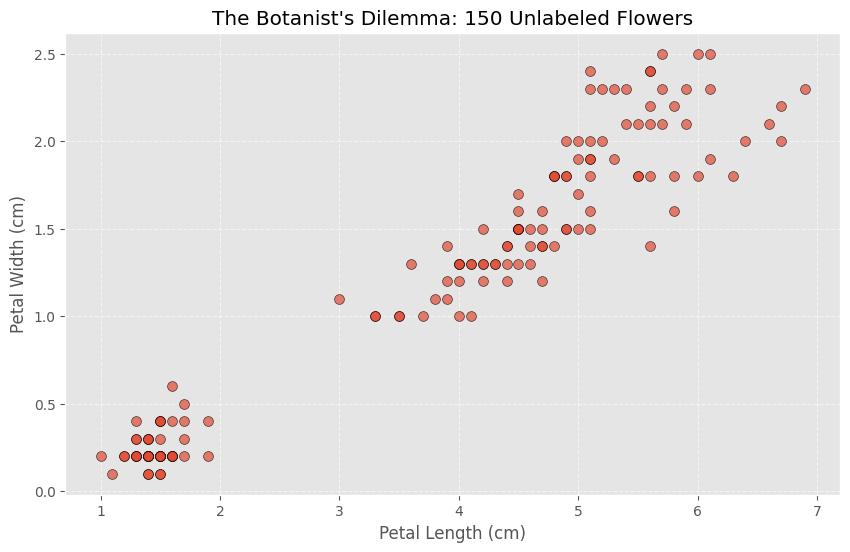

In [17]:
# Load real data
iris = load_iris()
X_full = iris.data

# Let's look at the data structure using Pandas for a better view
# This helps us understand what the features are before we start processing
df = pd.DataFrame(X_full, columns=iris.feature_names)
print("First 5 rows of the full dataset:")
display(df.head())

print("\nDataset Statistics:")
display(df.describe().loc[['mean', 'std', 'min', 'max']])

# --- PREPARING THE DATA FOR CLUSTERING ---

# To make visualization easy (so we can plot it on a 2D screen), 
# we will focus on the last two columns: Petal Length (cm) and Petal Width (cm).
# In reality, K-Means works in N-dimensions, but we want to SEE the clusters.
X_iris = X_full[:, 2:4]

# WE DISCARD THE LABELS (y). You are flying blind!
# We strictly do not use 'iris.target' here.
print(f"\nSubset shape used for clustering: {X_iris.shape}")

# Visualize the unlabeled data
plt.figure(figsize=(10, 6))
plt.scatter(X_iris[:, 0], X_iris[:, 1], s=50, alpha=0.7, edgecolors='k')
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("The Botanist's Dilemma: 150 Unlabeled Flowers")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### 3.0. **Visual Analysis: Reading the Scatter Plot**

Before you run your algorithm, look closely at the plot above.

1.  **Why are some dots darker than others?**
    In the code, we set `alpha=0.7`. This makes the markers semi-transparent.
    * **Light dots:** Represent a single flower with unique measurements.
    * **Dark dots:** Represent **Data Density**. These are multiple flowers that have the *exact same* petal length and width. They are stacked on top of each other. The darker the spot, the more flowers are clustered at that specific coordinate.

2.  **The Natural Structure:**
    Even without labels, your eyes can likely spot patterns:
    * There is a clearly isolated cluster in the bottom-left (Small Petals).
    * There is a larger, more diffuse cloud in the top-right (Large Petals).
    
    **The Question:** Is that top-right cloud one giant species? Or is it two species that are slightly overlapping? This is exactly what we will use the **Elbow Method** to find out.

### 3.1. **Finding the Optimal K (The Elbow Method) `#TODO`**

Is there 1 species? 2? 3? 5?
You must find out using **your** `SimpleKMeans` class.

**Task:**
1. Loop through $K = 1$ to $10$.
2. For each K, initialize and fit `SimpleKMeans` on `X_iris`.
3. Store the `inertia_`.
4. Plot the Elbow Curve.

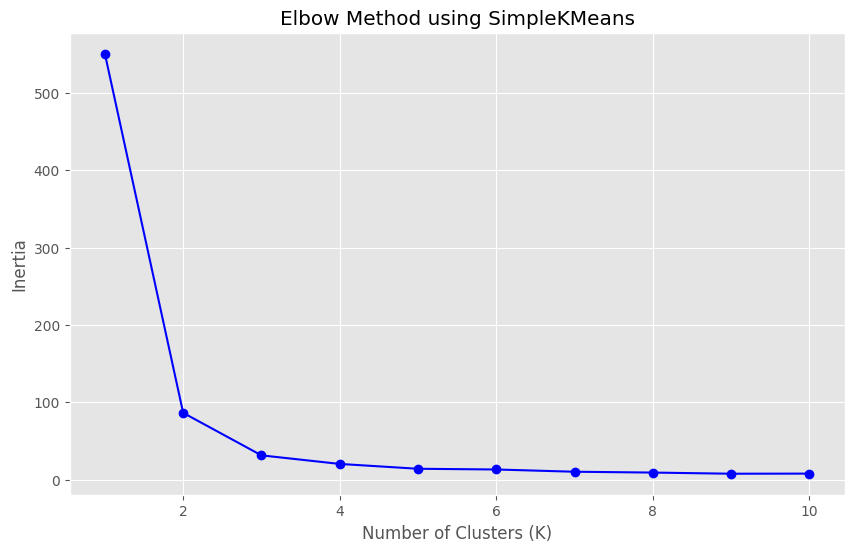

In [18]:
inertias = []
k_values = range(1, 11)

# TODO: Implement the loop using YOUR SimpleKMeans class
for k in k_values:
    # 1. Initialize SimpleKMeans with n_clusters=k and random_state=42
    # 2. Fit the model on X_iris
    # 3. Append the model's inertia_ to the 'inertias' list
    model = SimpleKMeans(n_clusters=k, random_state=42)
    model.fit(X_iris)
    inertias.append(model.inertia_)

# Plotting the Elbow Curve
plt.plot(k_values, inertias, 'bo-')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method using SimpleKMeans')
plt.show()

### 3.2. **Final Clustering & Interpretation `#TODO`**

**Task:**
1.  **Analyze:** Look at your Elbow curve from the previous step. Where does the inertia start to flatten out?
    * *Note:* Real-world data is messy. You might see a "soft" elbow where $K=2$ and $K=3$ both look reasonable. Make a choice that you think balances model complexity with performance.
2.  **Fit:** Initialize and train your `SimpleKMeans` with your chosen `optimal_k`.
3.  **Visualize:** Plot the resulting clusters and the centroids.

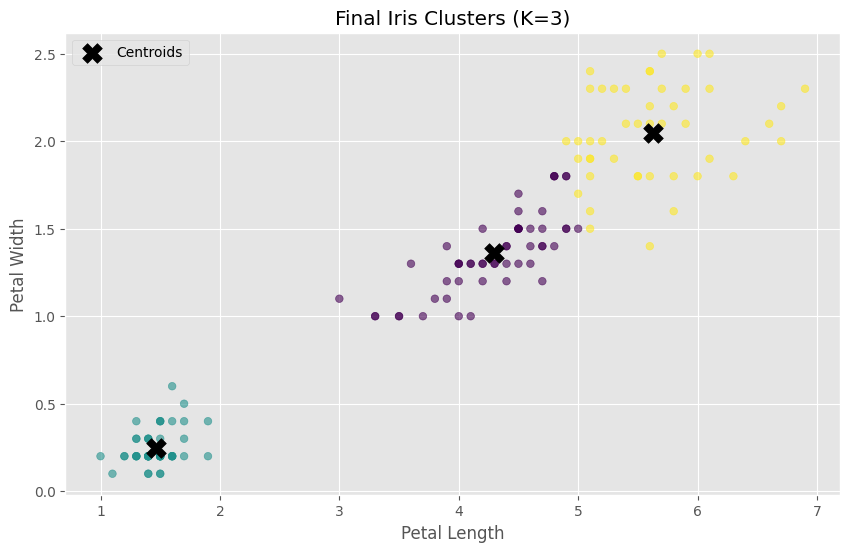

In [19]:
# TODO: Set your chosen K
optimal_k = 3 # e.g., 2, 3, 4...

# TODO: Fit the final model
final_model = SimpleKMeans(n_clusters=optimal_k, random_state=42)
final_model.fit(X_iris)

# Visualize the results
plt.figure(figsize=(10, 6))
# Data points
plt.scatter(X_iris[:, 0], X_iris[:, 1], c=final_model.labels, cmap='viridis', s=30, alpha=0.6)
# Centroids
plt.scatter(final_model.centroids[:, 0], final_model.centroids[:, 1], c='black', marker='X', s=200, label='Centroids')
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title(f"Final Iris Clusters (K={optimal_k})")
plt.legend(loc='upper left') # Legend moved to top left
plt.show()

### 3.3. **The Reveal: Accuracy Check**

In a truly unsupervised setting, you would stop here. You would name your clusters (e.g., "Small Flowers", "Giant Flowers") and go home. **However**, because this is the Iris dataset, we actually have the **Ground Truth** (the labels we hid from you earlier). Let's compare your unsupervised discovery against the biological reality.

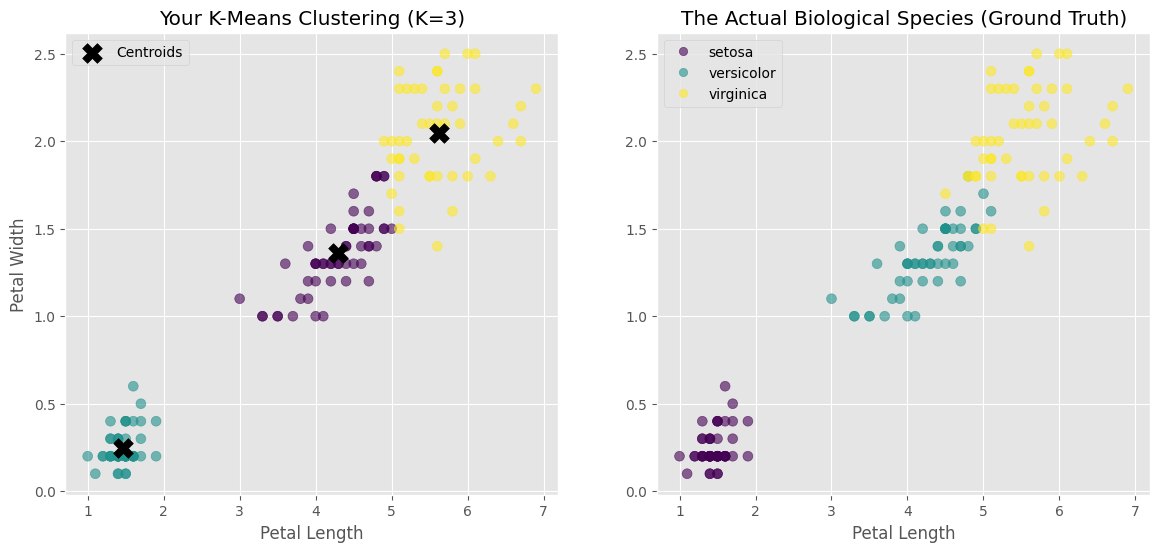

In [20]:
# Load the true labels we hid earlier
y_true = iris.target
target_names = iris.target_names

# --- Visual Comparison ---
plt.figure(figsize=(14, 6))

# Plot 1: Your K-Means Result
plt.subplot(1, 2, 1)
plt.scatter(X_iris[:, 0], X_iris[:, 1], c=final_model.labels, cmap='viridis', s=50, alpha=0.6)
plt.scatter(final_model.centroids[:, 0], final_model.centroids[:, 1], c='black', marker='X', s=200, label='Centroids')
plt.title(f"Your K-Means Clustering (K={optimal_k})")
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.legend(loc='upper left')

# Plot 2: The Ground Truth (Biological Species)
plt.subplot(1, 2, 2)
# Re-plot using the TRUE labels (y_true)
scatter = plt.scatter(X_iris[:, 0], X_iris[:, 1], c=y_true, cmap='viridis', s=50, alpha=0.6)
plt.title("The Actual Biological Species (Ground Truth)")
plt.xlabel("Petal Length")
plt.legend(handles=scatter.legend_elements()[0], labels=list(target_names), loc='upper left')

plt.show()

### 3.4. **Analysis: Where did K-Means fail? `#TODO`**

**Question:** Compare the two plots above.
1.  **The Perfect Match:** Which species was identified almost perfectly? Why was it easy for the algorithm?
2.  **The Mismatch:** Look at the boundary between *Versicolor* and *Virginica*. How does the **shape** of the K-Means boundary differ from the biological reality? (Hint: Think about the geometry).
3.  **The Colors:** Why are the colors (purple/yellow/green) likely different between your plot and the Ground Truth plot? Does this mean the clustering is wrong?

**Your Answer:**

1.  **The Perfect Match:**
    <p dir='rtl'>
    داده های مربوط به کلاس ستوسا به دلیل فاصله زیاد (نتیجه این که طول و عرض گلبرگ ها نسبت به دو گل دیگر کمتر است) از دیگر داده ها، به راحتی و به درستی تشخیص داده شدند
    </p>

2.  **The Mismatch:**
    <p dir='rtl'>
    همانطور که در تمرین های تئوری نشان داده شد مرز تصمیم برای k-means خطی است و در نتیجه هنگامی که ما دسته بندی انجام میدهیم با مرزی خطی این دو کلاس از هم جدا میشود در صورتی که در واقعیت مرز خطی نیست
    </p>

3.  **The Colors:**
    <p dir='rtl'>
    الگوریتم k-means رنگ ها را براساس مقداردهی اولیه به مرکز خوشه ها تعیین میکند که الزاما با رنگ واقعی یکسان نیست.
    </p>

---

## 4. **Part D: Object-Oriented Image Compression**

Clustering isn't just for data tables; it's a powerful tool for computer vision. An image is essentially a grid of pixels. In a color image, every pixel is a vector of 3 numbers: `[Red, Green, Blue]`.
If you have a 12 megapixel photo, you have 12 million data points in 3D space.

**The Concept:**
If we cluster these 12 million colors into just **K=16 clusters**, we can identify the 16 "dominant" colors of the image. By replacing every pixel with its nearest cluster centroid, we drastically reduce the information needed to store the image. This is a form of **Lossy Compression**.

### 4.1. **Implementing the Compressor `#TODO`**

**Task:**
You will build a professional class `ImageCompressor` that:
1.  Takes an image.
2.  Learns the palette (fits K-Means).
3.  Repaints the image using only the learned palette.

In [21]:
class ImageCompressor:
    def __init__(self, n_colors=16):
        """
        Initializes the compressor with a target number of colors.
        """
        self.n_colors = n_colors
        # We use a fixed random_state for reproducibility
        self.kmeans = KMeans(n_clusters=n_colors, n_init=5, random_state=42)
        self.original_shape = None
        
    def fit(self, image):
        """
        Fits the K-Means model to the colors in the image.
        1. Store original shape.
        2. Flatten image to a list of pixels (N_pixels, 3).
        3. Normalize 0-255 to 0-1 if necessary.
        4. Fit K-Means.
        """
        self.original_shape = image.shape
        
        # TODO: Reshape image to 2D array: (Height * Width, 3 Channels)
        image_reshaped = image.reshape(-1, 3)
        
        # Check if we need to normalize (if max value > 1, divide by 255.0)
        # TODO: Normalize if needed
        if image_reshaped.max() > 1.0:
            image_reshaped = image_reshaped / 255.0
        
        # TODO: Fit self.kmeans to the reshaped image
        self.kmeans.fit(image_reshaped)
        
    def get_compressed_image(self):
        """
        Reconstructs the image by replacing every pixel with its cluster center.
        """
        # TODO: Get the new colors (centroids) for each pixel label
        # Hint: Use self.kmeans.cluster_centers_ and self.kmeans.labels_
        new_colors = self.kmeans.cluster_centers_[self.kmeans.labels_]
        
        # TODO: Reshape this array back to the self.original_shape
        # return ...
        return new_colors.reshape(self.original_shape)

### 4.2. **Running the Compressor `#TODO`**

Now, test your class. We will use a standard sample image (the "Astronaut") provided by the `skimage` library, so we don't have to worry about broken URLs.

**Task:**
1.  Initialize `ImageCompressor` with **K=24** colors.
2.  Fit it to the `img` provided.
3.  Get the compressed version.
4.  Run the plotting cell to compare them.

In [24]:
# Load sample image
img = data.astronaut()

# TODO: Create an instance of ImageCompressor with 24 colors
compressor = ImageCompressor(n_colors=24)

# TODO: Fit the model to 'img'
# ...
compressor.fit(img)

# TODO: Get the compressed image
compressed_img = compressor.get_compressed_image()

print("Compression complete.")

Compression complete.


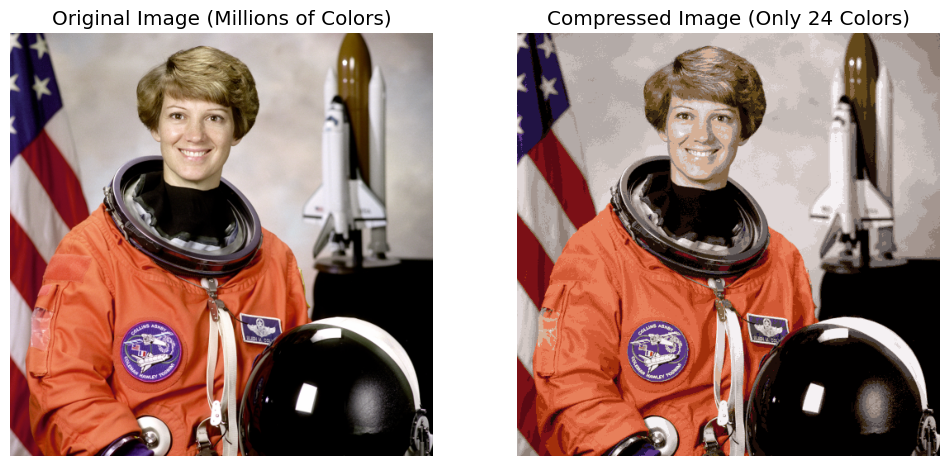

In [25]:
# --- Visualization ---
fig, ax = plt.subplots(1, 2, figsize=(12, 8))

ax[0].imshow(img)
ax[0].set_title("Original Image (Millions of Colors)")
ax[0].axis('off')

ax[1].imshow(compressed_img)
ax[1].set_title("Compressed Image (Only 24 Colors)")
ax[1].axis('off')

plt.show()

<div style="background-color: #e6f7ff; padding: 20px; border-radius: 10px; border: 1px solid #b3e0ff; text-align: center;">
  <h3 style="margin:0; color:#0056b3;">Congratulations!</h3>
  <p style="color:#333; font-size: 1.1em;">You have completed the fifth practical homework.</p>
</div>